Step 1

In [2]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Import library
import pandas as pd
import os

# 3. Definisikan path dataset
file_path = '/content/drive/MyDrive/FOLDER KULIAH S2 LESGO/ADV Machine Learning/data_tiket.csv'

# 4. Cek apakah file ada
if not os.path.exists(file_path):
    raise FileNotFoundError(f"❌ File tidak ditemukan di: {file_path}\n"
                            "Pastikan path Google Drive sudah benar (huruf besar/kecil & spasi).")
else:
    print(f"✅ File ditemukan: {file_path}")
    print(f"📦 Ukuran file: {os.path.getsize(file_path) / (1024*1024):.2f} MB")

Mounted at /content/drive
✅ File ditemukan: /content/drive/MyDrive/FOLDER KULIAH S2 LESGO/ADV Machine Learning/data_tiket.csv
📦 Ukuran file: 3.09 MB


Step 2

In [3]:
!pip install gensim scikit-learn tensorflow pandas numpy matplotlib seaborn

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

# ML Tradisional
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Deep Learning
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout, SpatialDropout1D

# Evaluasi
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, accuracy_score,
                             f1_score, precision_score, recall_score,
                             confusion_matrix)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 36.0 MB/s  0:00:00


Step 3

In [4]:
# Load dataset dengan parameter yang disesuaikan untuk multi-line quoted fields
# PERBAIKAN: Ganti encoding menjadi 'latin-1' untuk menangani byte 0xa0
df = pd.read_csv(
    file_path,
    sep=';',                    # Separator titik koma
    header=None,                # Tidak ada header
    names=['ID', 'Deskripsi', 'Kategori', 'Timestamp'],
    quotechar='"',              # Karakter kutip pembungkus field
    engine='python',            # Engine python lebih robust untuk multi-line
    on_bad_lines='skip',        # Skip baris yang formatnya rusak
    encoding='latin-1'          # <-- PERBAIKAN DI SINI
)

print(f"✅ Berhasil memuat {len(df):,} baris data.")
print(f"✅ Jumlah kolom: {len(df.columns)}")
print(f"✅ Kolom: {list(df.columns)}")

# Cek missing values
print("\n📊 Missing Values:")
print(df.isnull().sum())

# Preview 3 baris pertama
print("\n📊 Preview Data:")
display(df.head(3))

✅ Berhasil memuat 6,559 baris data.
✅ Jumlah kolom: 4
✅ Kolom: ['ID', 'Deskripsi', 'Kategori', 'Timestamp']

📊 Missing Values:
ID            53
Deskripsi     53
Kategori      57
Timestamp    188
dtype: int64

📊 Preview Data:


,ID,Deskripsi,Kategori,Timestamp
0,NOMOR TIKET,URAIAN TIKET,KATEGORI TIKET,WAKTU REKAM
1,J73A0B518C,mohon bantuanya pib CV SURYA AUTO LESTARI AJU ...,PIB - Lainnya,2026-10-14 13:39:37.914
2,DFAFE2724A,"Yth. IKC (PLD), sehubungan dengan nota dinas D...",Barang kiriman - Lainnya,2026-10-08 14:48:52.253


Step 4

In [5]:
import re
import pandas as pd

def clean_and_mask_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # ==============================================================================
    # 1. MASKING DATA SENSITIF (Mencegah Model Menghafal ID / Shortcut Learning)
    # ==============================================================================

    # Masking NPWP (15-20 digit angka, kadang ada titik atau strip)
    text = re.sub(r'\b\d{2}\.?\d{3}\.?\d{3}\.?\d{1}-?\d{3}\.?\d{3}\b', '<NPWP>', text)
    text = re.sub(r'\b\d{15,20}\b', '<NPWP>', text) # Catch-all untuk angka 15-20 digit

    # Masking Nomor Aju / Pengajuan (Alphanumeric, 18-30 karakter)
    # Contoh: 20120140DF5820260923000004, 000020ESC27720261005812142
    text = re.sub(r'\b[A-Z0-9]{18,30}\b', '<NO_AJU>', text)

    # Masking Nomor Kontainer (4 huruf kapital diikuti 7 angka, e.g., EGSU3850344)
    text = re.sub(r'\b[A-Z]{4}\d{7}\b', '<CONTAINER>', text)

    # Masking NTPN / Kode Billing / No Referensi (Alphanumeric 16-20 karakter)
    text = re.sub(r'\b[A-Z0-9]{16,20}\b', '<BILLING>', text)

    # ==============================================================================
    # 2. PEMBERSIHAN HTML & KARAKTER SPESIAL
    # ==============================================================================
    text = re.sub(r'<br\s*/?>|&lt;br/&gt;', ' ', text)
    text = re.sub(r'&nbsp;|&amp;|&quot;|&lt;|&gt;|&#39;|&mdash;|&ndash;|&rdquo;|&ldquo;', ' ', text)

    # ==============================================================================
    # 3. PEMBERSIHAN NOISE JSON (Opsional, tapi sangat disarankan)
    # ==============================================================================
    # Menghapus key JSON umum yang tidak memberi makna semantik untuk prioritas
    text = re.sub(r'"seriBarang"|"kodeJenisPungutan"|"nilaiBayar"|"tarifFasilitas"|"uraian"', ' ', text)

    # ==============================================================================
    # 4. NORMALISASI TEKS
    # ==============================================================================
    text = re.sub(r'https?://\S+|www\.\S+', '<URL>', text) # Masking URL
    text = re.sub(r'[^\w\s]', ' ', text) # Hapus tanda baca
    text = re.sub(r'\s+', ' ', text).strip().lower() # Normalisasi spasi dan lowercase

    return text

# Terapkan fungsi ke dataframe
print("⏳ Sedang melakukan advanced cleaning & masking...")
df['Deskripsi_Clean'] = df['Deskripsi'].apply(clean_and_mask_text)

# Filter data yang valid
df = df.dropna(subset=['Deskripsi_Clean'])
df = df[df['Deskripsi_Clean'].str.len() > 15] # Filter teks yang terlalu pendek (noise/sampah)

print(f"✅ Data setelah advanced cleaning & masking: {len(df):,} baris.")

# Preview hasil masking untuk validasi
print("\n📊 Preview Hasil Masking (Perhatikan bagaimana ID diganti dengan token):")
preview_df = df[['Deskripsi', 'Deskripsi_Clean']].head(3)
for idx, row in preview_df.iterrows():
    print(f"\n--- Baris {idx+1} ---")
    print(f"ASLI   : {row['Deskripsi'][:150]}...")
    print(f"CLEAN  : {row['Deskripsi_Clean'][:150]}...")

⏳ Sedang melakukan advanced cleaning & masking...
✅ Data setelah advanced cleaning & masking: 6,496 baris.

📊 Preview Hasil Masking (Perhatikan bagaimana ID diganti dengan token):

--- Baris 2 ---
ASLI   : mohon bantuanya pib CV SURYA AUTO LESTARI AJU 000020CVU19520260908100029 riject dengan alasan &lt;br/&gt;&lt;br/&gt;1. DOKUMEN E-SKA NO.E2673637651000...
CLEAN  : mohon bantuanya pib cv surya auto lestari aju no_aju riject dengan alasan 1 dokumen e ska no billing tanggal 2026 09 18 telah digunakan...

--- Baris 3 ---
ASLI   : Yth. IKC (PLD), sehubungan dengan nota dinas Direktur IKC nomor ND-381/BC.07/2025, kami mengajukan permohonan rollback status atas CN nomor EN53914858...
CLEAN  : yth ikc pld sehubungan dengan nota dinas direktur ikc nomor nd 381 bc 07 2025 kami mengajukan permohonan rollback status atas cn nomor en539148584jp d...

--- Baris 4 ---
ASLI   : Nama Perusahaan : PT Pabrik Sigaret Sriwidjaja&lt;br/&gt;Username : pssriwidjaja&lt;br/&gt;Kendala : upload laporan CK4 men

Step 5 dan 6

In [6]:
import re
import pandas as pd
from sklearn.model_selection import train_test_split

# --- STEP 5: PELABELAN PRIORITAS ---
def assign_priority(text):
    text = str(text).lower()
    if re.search(r'\b(urgent|segera|stuck|blokir|gagal login|error|gagal|reject|ditolak|sangkut|blank|tidak muncul|hilang|deadline|critical)\b', text):
        return 2  # High
    elif re.search(r'\b(mohon bantu|kendala|reset|perubahan|perbaikan|penelitian|revisi|informasi|mohon|bantu|tolong)\b', text):
        return 1  # Medium
    else:
        return 0  # Low

df['Priority_Label'] = df['Deskripsi_Clean'].apply(assign_priority)
print("📊 Distribusi Label Prioritas:")
print(df['Priority_Label'].value_counts().sort_index())

# --- STEP 6: SPLIT DATA ---
X_train, X_test, y_train, y_test = train_test_split(
    df['Deskripsi_Clean'],
    df['Priority_Label'],
    test_size=0.2,
    random_state=42,
    stratify=df['Priority_Label']
)
print(f"\n✅ Data Train: {len(X_train):,} baris | Data Test: {len(X_test):,} baris")

📊 Distribusi Label Prioritas:
Priority_Label
0     671
1    3437
2    2388
Name: count, dtype: int64

✅ Data Train: 5,196 baris | Data Test: 1,300 baris


Step 7 Training Machine Learning Tradisional

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Inisialisasi dictionary hasil
results_all = {}
label_names = ['Low (0)', 'Medium (1)', 'High (2)']

# TF-IDF
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1,2), sublinear_tf=True, min_df=2)

models_ml = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', C=1.0),
    'Linear SVM': LinearSVC(class_weight='balanced', max_iter=10000, C=1.0),
    'Naive Bayes': MultinomialNB(alpha=0.1),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)
}

print("="*60)
print("🚀 TRAINING ML TRADISIONAL")
print("="*60)

for name, model in models_ml.items():
    print(f"\n📌 Training: {name}")
    pipe = Pipeline([('tfidf', tfidf), ('clf', model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    results_all[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted'),
        'Recall': recall_score(y_test, y_pred, average='weighted'),
        'F1-Weighted': f1_score(y_test, y_pred, average='weighted'),
        'F1-Macro': f1_score(y_test, y_pred, average='macro'),
        'y_pred': y_pred
    }
    print(f"   Accuracy: {results_all[name]['Accuracy']:.4f} | F1-Macro: {results_all[name]['F1-Macro']:.4f}")

🚀 TRAINING ML TRADISIONAL

📌 Training: Logistic Regression
   Accuracy: 0.9154 | F1-Macro: 0.8866

📌 Training: Linear SVM
   Accuracy: 0.9269 | F1-Macro: 0.8830

📌 Training: Naive Bayes
   Accuracy: 0.7608 | F1-Macro: 0.6163

📌 Training: Random Forest
   Accuracy: 0.8785 | F1-Macro: 0.8598


Step 8

In [8]:
# Download FastText Indonesia
!wget -q https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.id.300.vec.gz
!gunzip -f cc.id.300.vec.gz

from gensim.models import KeyedVectors
print("\n📥 Loading FastText Indonesia... (butuh ~1-2 menit)")
fasttext_id = KeyedVectors.load_word2vec_format('cc.id.300.vec', limit=200000)
print(f"✅ Vocabulary loaded: {len(fasttext_id):,} words, dim: {fasttext_id.vector_size}")


📥 Loading FastText Indonesia... (butuh ~1-2 menit)
✅ Vocabulary loaded: 200,000 words, dim: 300


Step 9 & 10 Persiapan & Training Bi-LSTM

In [9]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout, SpatialDropout1D
from sklearn.utils.class_weight import compute_class_weight

MAX_WORDS = 20000
MAX_LEN = 150
EMBEDDING_DIM = 300
NUM_CLASSES = 3

# Tokenisasi
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)
word_index = tokenizer.word_index

# Embedding Matrix
embedding_matrix = np.zeros((MAX_WORDS, EMBEDDING_DIM))
found = 0
for word, i in word_index.items():
    if i >= MAX_WORDS: continue
    if word in fasttext_id:
        embedding_matrix[i] = fasttext_id[word]
        found += 1
print(f"✅ Kata ditemukan di FastText: {found}/{MAX_WORDS} ({found/MAX_WORDS*100:.1f}%)")

# Pad Sequences
X_train_pad = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=MAX_LEN)
X_test_pad = pad_sequences(tokenizer.texts_to_sequences(X_test), maxlen=MAX_LEN)

# Class Weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train.values), y=y_train.values)
class_weight_dict = {i: class_weights[i] for i in range(len(class_weights))}

# Arsitektur Bi-LSTM
model_lstm = Sequential([
    Embedding(MAX_WORDS, EMBEDDING_DIM, weights=[embedding_matrix], trainable=True, input_length=MAX_LEN),
    SpatialDropout1D(0.2),
    Bidirectional(LSTM(128, return_sequences=True, dropout=0.2, recurrent_dropout=0.2)),
    Bidirectional(LSTM(64, dropout=0.2, recurrent_dropout=0.2)),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

model_lstm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])

print("\n🚀 Training Bi-LSTM...")
history = model_lstm.fit(
    X_train_pad, y_train, epochs=10, batch_size=64,
    validation_data=(X_test_pad, y_test), class_weight=class_weight_dict,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)],
    verbose=1
)

# Evaluasi Bi-LSTM
y_pred_lstm = model_lstm.predict(X_test_pad).argmax(axis=-1)
results_all['Bi-LSTM (FastText)'] = {
    'Accuracy': accuracy_score(y_test, y_pred_lstm),
    'Precision': precision_score(y_test, y_pred_lstm, average='weighted'),
    'Recall': recall_score(y_test, y_pred_lstm, average='weighted'),
    'F1-Weighted': f1_score(y_test, y_pred_lstm, average='weighted'),
    'F1-Macro': f1_score(y_test, y_pred_lstm, average='macro'),
    'y_pred': y_pred_lstm
}
print(f"\n✅ Bi-LSTM Selesai. Accuracy: {results_all['Bi-LSTM (FastText)']['Accuracy']:.4f}")

✅ Kata ditemukan di FastText: 6761/20000 (33.8%)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(



🚀 Training Bi-LSTM...
Epoch 1/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 312s 3s/step - accuracy: 0.4846 - loss: 0.9250 - val_accuracy: 0.6223 - val_loss: 0.7474
Epoch 2/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 285s 3s/step - accuracy: 0.7371 - loss: 0.4982 - val_accuracy: 0.9115 - val_loss: 0.2972
Epoch 3/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 306s 3s/step - accuracy: 0.9271 - loss: 0.2482 - val_accuracy: 0.9446 - val_loss: 0.2062
Epoch 4/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 279s 3s/step - accuracy: 0.9742 - loss: 0.1081 - val_accuracy: 0.9615 - val_loss: 0.1608
Epoch 5/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 274s 3s/step - accuracy: 0.9833 - loss: 0.0679 - val_accuracy: 0.9523 - val_loss: 0.1879
Epoch 6/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 275s 3s/step - accuracy: 0.9833 - loss: 0.0672 - val_accuracy: 0.9538 - val_loss: 0.2035
41/41 ━━━━━━━━━━━━━━━━━━━━ 18s 394ms/step

✅ Bi-LSTM Selesai. Accuracy: 0.9615


STEP 9

✅ Data hasil evaluasi ditemukan untuk model: ['Logistic Regression', 'Linear SVM', 'Naive Bayes', 'Random Forest', 'Bi-LSTM (FastText)']

📊 TABEL PERBANDINGAN MODEL KLASIFIKASI PRIORITAS TIKET CEISACARE


,Accuracy,Precision,Recall,F1-Weighted,F1-Macro
Logistic Regression,91.54,91.72,91.54,91.59,88.66
Linear SVM,92.69,92.74,92.69,92.50,88.30
Naive Bayes,76.08,77.40,76.08,73.83,61.63
Random Forest,87.85,89.19,87.85,87.62,85.98
Bi-LSTM (FastText),96.15,96.21,96.15,96.16,95.53


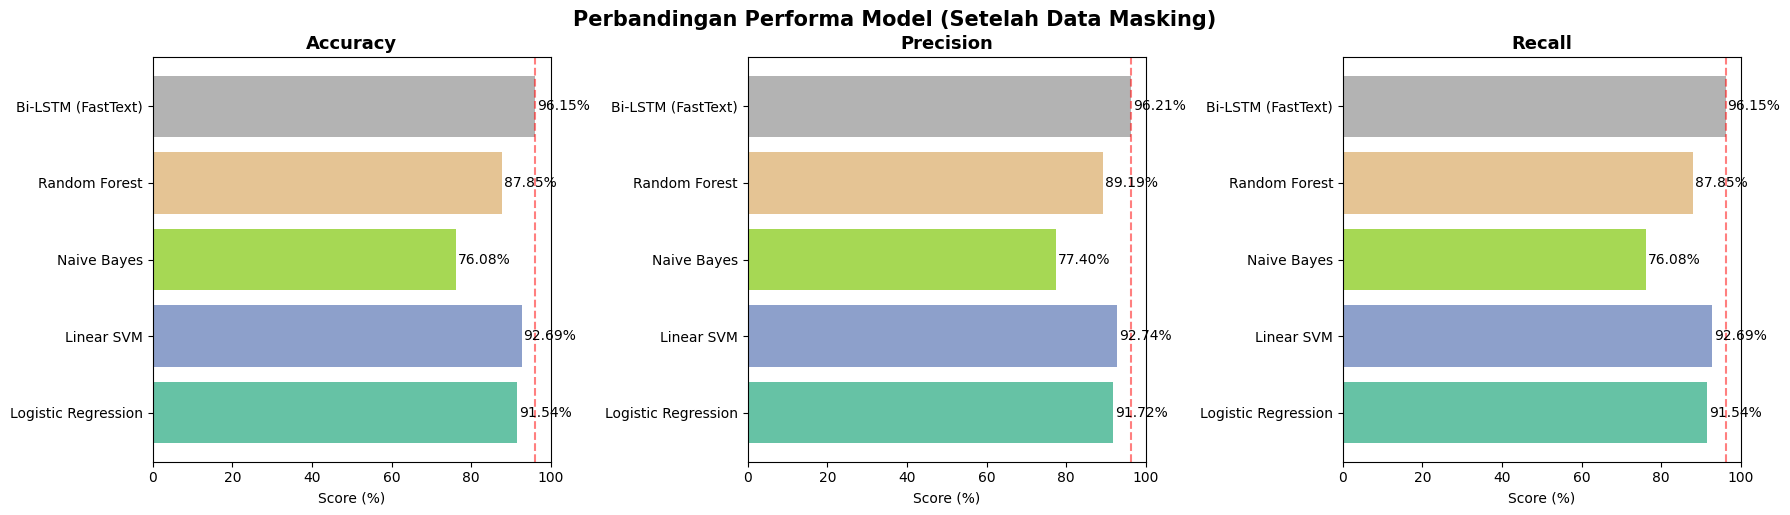

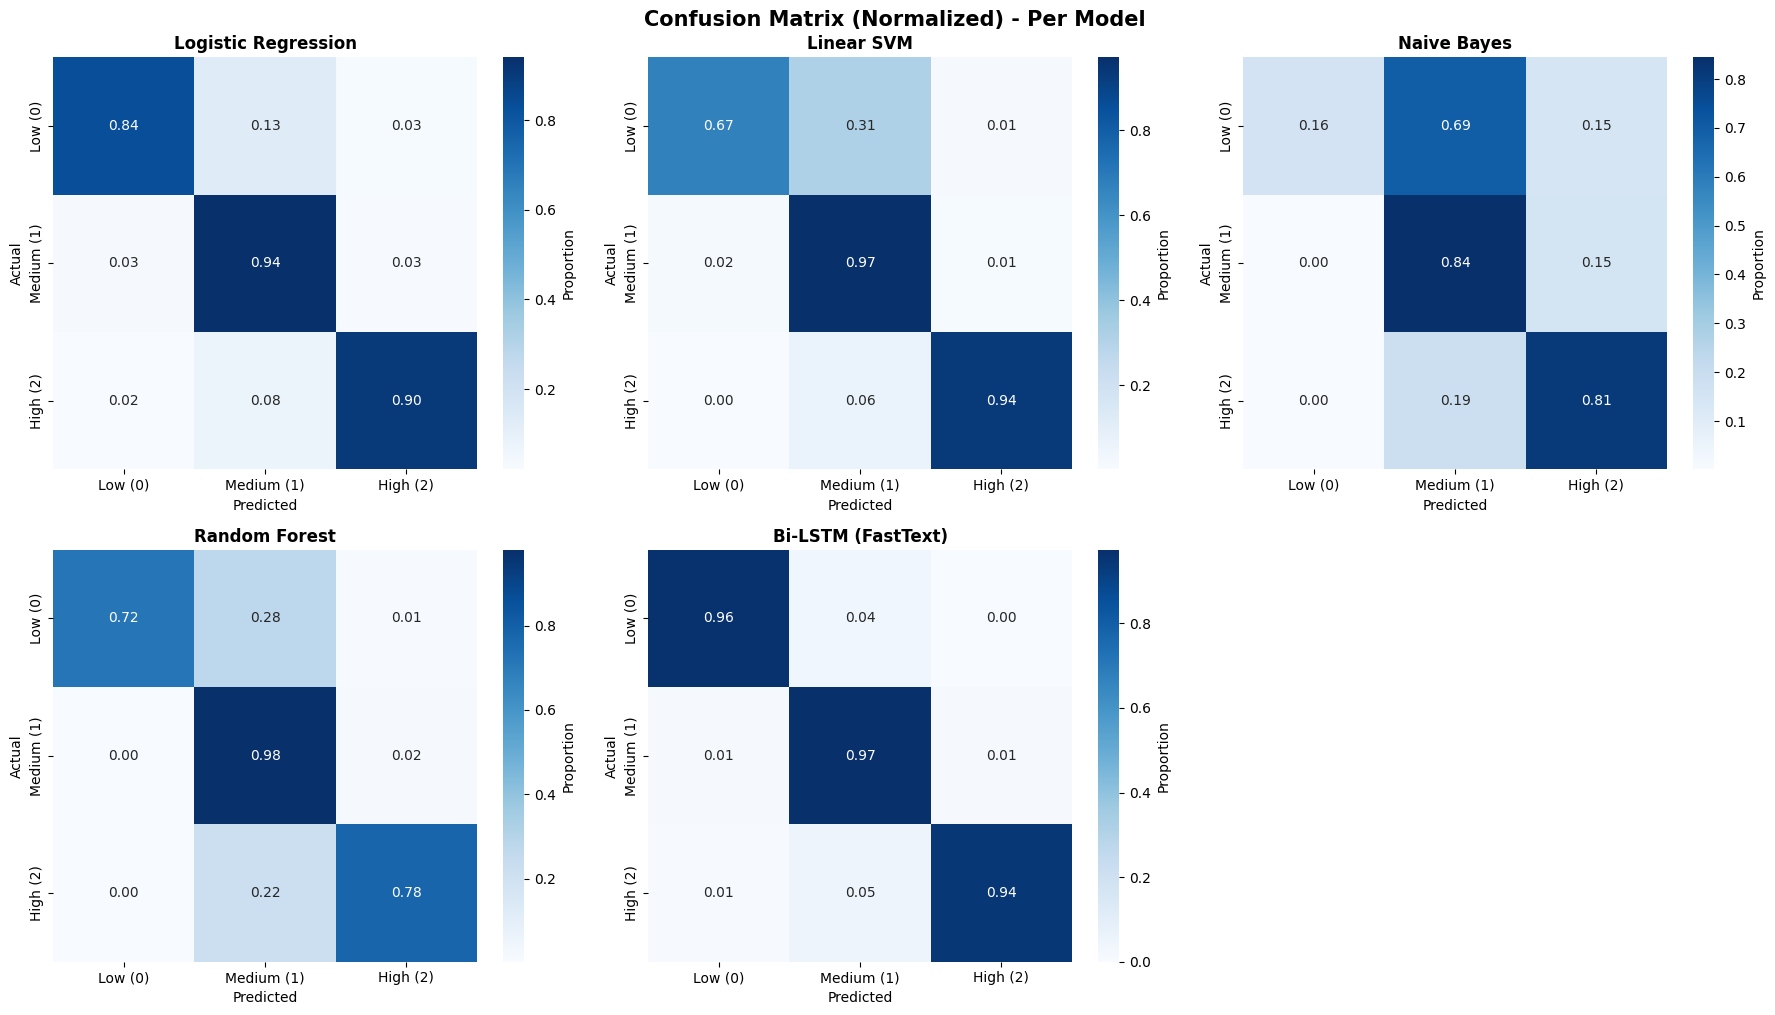

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ==============================================================================
# 1. SANITY CHECK: Memastikan data hasil training ada
# ==============================================================================
if 'results_all' not in locals() or not results_all:
    raise RuntimeError("❌ Variabel 'results_all' kosong atau belum didefinisikan! "
                       "Anda WAJIB menjalankan Step 7 (ML Tradisional) dan Step 10 (Bi-LSTM) "
                       "terlebih dahulu di session Colab ini sebelum menjalankan Step 11.")

print("✅ Data hasil evaluasi ditemukan untuk model:", list(results_all.keys()))

# ==============================================================================
# 2. MEMBUAT TABEL PERBANDINGAN (Cara yang lebih aman & sederhana)
# ==============================================================================
metrics_to_show = ['Accuracy', 'Precision', 'Recall', 'F1-Weighted', 'F1-Macro']
clean_results = {}

for model_name, metrics in results_all.items():
    # Ambil hanya metrik yang dibutuhkan, abaikan array 'y_pred' yang besar
    clean_results[model_name] = {k: metrics.get(k, 0) for k in metrics_to_show}

df_results = pd.DataFrame(clean_results).T
df_results = (df_results * 100).round(2)

print("\n" + "="*80)
print("📊 TABEL PERBANDINGAN MODEL KLASIFIKASI PRIORITAS TIKET CEISACARE")
print("="*80)
display(df_results)

# ==============================================================================
# 3. VISUALISASI BAR CHART
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = plt.cm.Set2(np.linspace(0, 1, len(df_results)))

for idx, metric in enumerate(metrics_to_show[:3]): # Ambil 3 metrik utama
    ax = axes[idx]
    bars = ax.barh(df_results.index, df_results[metric], color=colors)
    ax.set_xlim(0, 100)
    ax.set_xlabel('Score (%)')
    ax.set_title(metric, fontweight='bold', fontsize=13)
    ax.axvline(x=df_results[metric].max(), color='red', linestyle='--', alpha=0.5)

    for bar, val in zip(bars, df_results[metric]):
        ax.text(val + 0.5, bar.get_y() + bar.get_height()/2,
                f'{val:.2f}%', va='center', fontsize=10)

plt.tight_layout()
plt.suptitle('Perbandingan Performa Model (Setelah Data Masking)',
             fontsize=15, fontweight='bold', y=1.02)
plt.show()

# ==============================================================================
# 4. VISUALISASI CONFUSION MATRIX
# ==============================================================================
label_names = ['Low (0)', 'Medium (1)', 'High (2)']
n_models = len(results_all)
cols = 3
rows = (n_models + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
axes = axes.flatten()

for idx, (name, res) in enumerate(results_all.items()):
    ax = axes[idx]
    y_pred = res['y_pred']

    cm = confusion_matrix(y_test, y_pred)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=label_names, yticklabels=label_names, ax=ax,
                cbar_kws={'label': 'Proportion'})
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

# Sembunyikan subplot kosong jika jumlah model < 6
for j in range(idx + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.suptitle('Confusion Matrix (Normalized) - Per Model',
             fontsize=15, fontweight='bold', y=1.01)
plt.show()

STEP 10

In [12]:
from sklearn.metrics import classification_report
import pandas as pd

# Pastikan variabel y_test dan y_pred_lstm sudah ada dari hasil training sebelumnya
# Jika belum, pastikan Anda sudah menjalankan cell training Bi-LSTM

# Generate classification report sebagai dictionary
report_dict = classification_report(y_test, y_pred_lstm, target_names=['Low (0)', 'Medium (1)', 'High (2)'], output_dict=True)

# Konversi ke DataFrame agar rapi
df_class_report = pd.DataFrame(report_dict).transpose()

# Format menjadi persentase dan bulatkan 2 desimal
df_class_report = (df_class_report * 100).round(2)

print("📊 TABEL 3: PER-CLASS PERFORMANCE (Salin angka di bawah ini ke Paper Anda)")
print(df_class_report[['precision', 'recall', 'f1-score', 'support']].to_markdown())

📊 TABEL 3: PER-CLASS PERFORMANCE (Salin angka di bawah ini ke Paper Anda)
|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Low (0)      |       91.49 |    96.27 |      93.82 |  13400    |
| Medium (1)   |       95.85 |    97.38 |      96.61 |  68800    |
| High (2)     |       98.04 |    94.35 |      96.16 |  47800    |
| accuracy     |       96.15 |    96.15 |      96.15 |     96.15 |
| macro avg    |       95.13 |    96    |      95.53 | 130000    |
| weighted avg |       96.21 |    96.15 |      96.16 | 130000    |


🔍 Struktur results_all:
  Logistic Regression: ['Accuracy', 'Precision', 'Recall', 'F1-Weighted', 'F1-Macro', 'y_pred']
  Linear SVM: ['Accuracy', 'Precision', 'Recall', 'F1-Weighted', 'F1-Macro', 'y_pred']
  Naive Bayes: ['Accuracy', 'Precision', 'Recall', 'F1-Weighted', 'F1-Macro', 'y_pred']
  Random Forest: ['Accuracy', 'Precision', 'Recall', 'F1-Weighted', 'F1-Macro', 'y_pred']
  Bi-LSTM (FastText): ['Accuracy', 'Precision', 'Recall', 'F1-Weighted', 'F1-Macro', 'y_pred']

📊 TABEL PERBANDINGAN MODEL KLASIFIKASI PRIORITAS TIKET CEISACARE


,Accuracy,Precision,Recall,F1-Weighted,F1-Macro
Logistic Regression,91.70,91.82,91.70,91.74,88.35
Linear SVM,93.54,93.66,93.54,93.40,90.32
Naive Bayes,76.40,77.31,76.40,74.56,63.90
Random Forest,89.24,90.32,89.24,89.01,85.89
Bi-LSTM (FastText),97.85,97.84,97.85,97.84,97.18


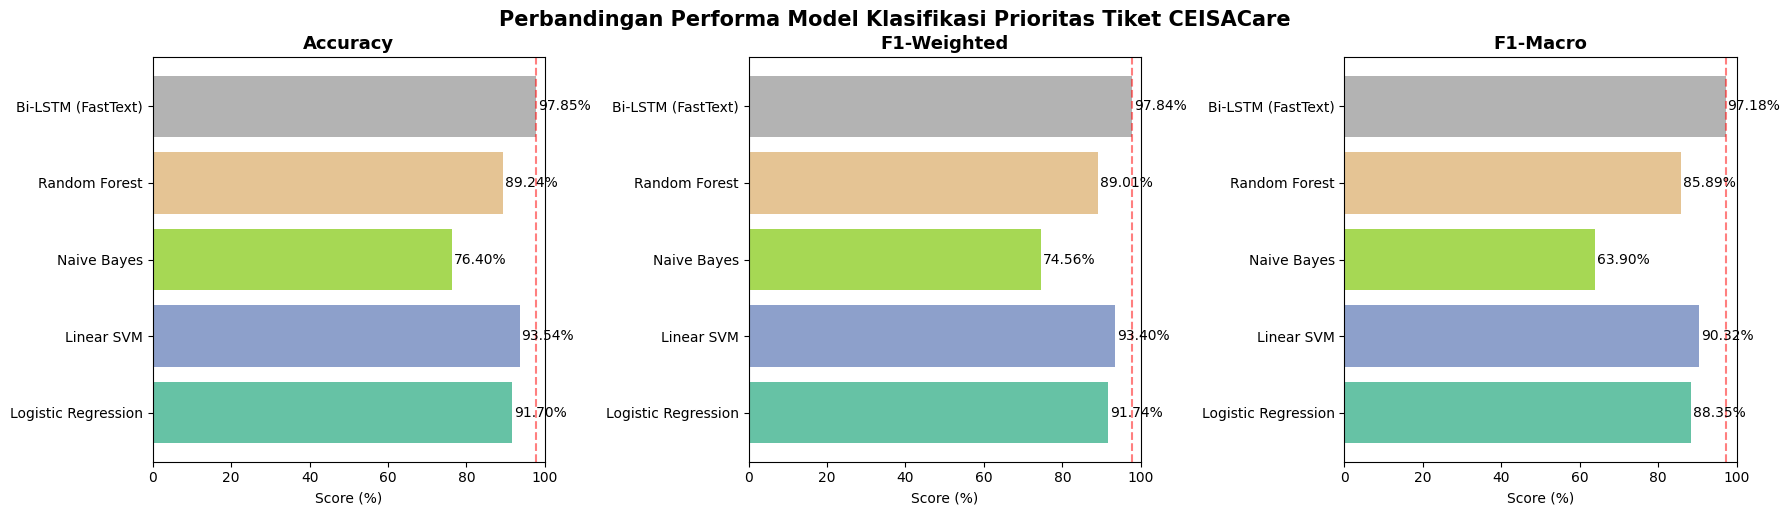

In [ ]:
# Import library yang diperlukan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cek apakah results_all sudah ada
if 'results_all' not in dir():
    raise NameError("❌ Variabel 'results_all' tidak ditemukan. "
                    "Pastikan Anda sudah menjalankan Step 7 (ML Tradisional) dan Step 9 (Bi-LSTM) terlebih dahulu.")

# Cek struktur results_all
print("🔍 Struktur results_all:")
for model_name, metrics in results_all.items():
    print(f"  {model_name}: {list(metrics.keys())}")

# Pastikan semua model memiliki kunci yang diperlukan
required_keys = ['Accuracy', 'Precision', 'Recall', 'F1-Weighted', 'F1-Macro']
for model_name, metrics in results_all.items():
    missing_keys = [k for k in required_keys if k not in metrics]
    if missing_keys:
        print(f"⚠️ Model '{model_name}' tidak memiliki kunci: {missing_keys}")

# Buat DataFrame dengan cara yang lebih aman
data_for_df = {}
for model_name, metrics in results_all.items():
    data_for_df[model_name] = {
        'Accuracy': metrics.get('Accuracy', 0),
        'Precision': metrics.get('Precision', 0),
        'Recall': metrics.get('Recall', 0),
        'F1-Weighted': metrics.get('F1-Weighted', 0),
        'F1-Macro': metrics.get('F1-Macro', 0)
    }

df_results = pd.DataFrame(data_for_df).T
df_results = (df_results * 100).round(2)

print("\n" + "="*80)
print("📊 TABEL PERBANDINGAN MODEL KLASIFIKASI PRIORITAS TIKET CEISACARE")
print("="*80)
display(df_results)

# Bar chart perbandingan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics_to_plot = ['Accuracy', 'F1-Weighted', 'F1-Macro']
colors = plt.cm.Set2(np.linspace(0, 1, len(df_results)))

for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx]
    bars = ax.barh(df_results.index, df_results[metric], color=colors)
    ax.set_xlim(0, 100)
    ax.set_xlabel('Score (%)')
    ax.set_title(metric, fontweight='bold', fontsize=13)
    ax.axvline(x=df_results[metric].max(), color='red', linestyle='--', alpha=0.5)

    for bar, val in zip(bars, df_results[metric]):
        ax.text(val + 0.5, bar.get_y() + bar.get_height()/2,
                f'{val:.2f}%', va='center', fontsize=10)

plt.tight_layout()
plt.suptitle('Perbandingan Performa Model Klasifikasi Prioritas Tiket CEISACare',
             fontsize=15, fontweight='bold', y=1.02)
plt.savefig('comparison_chart.png', dpi=150, bbox_inches='tight')
plt.show()

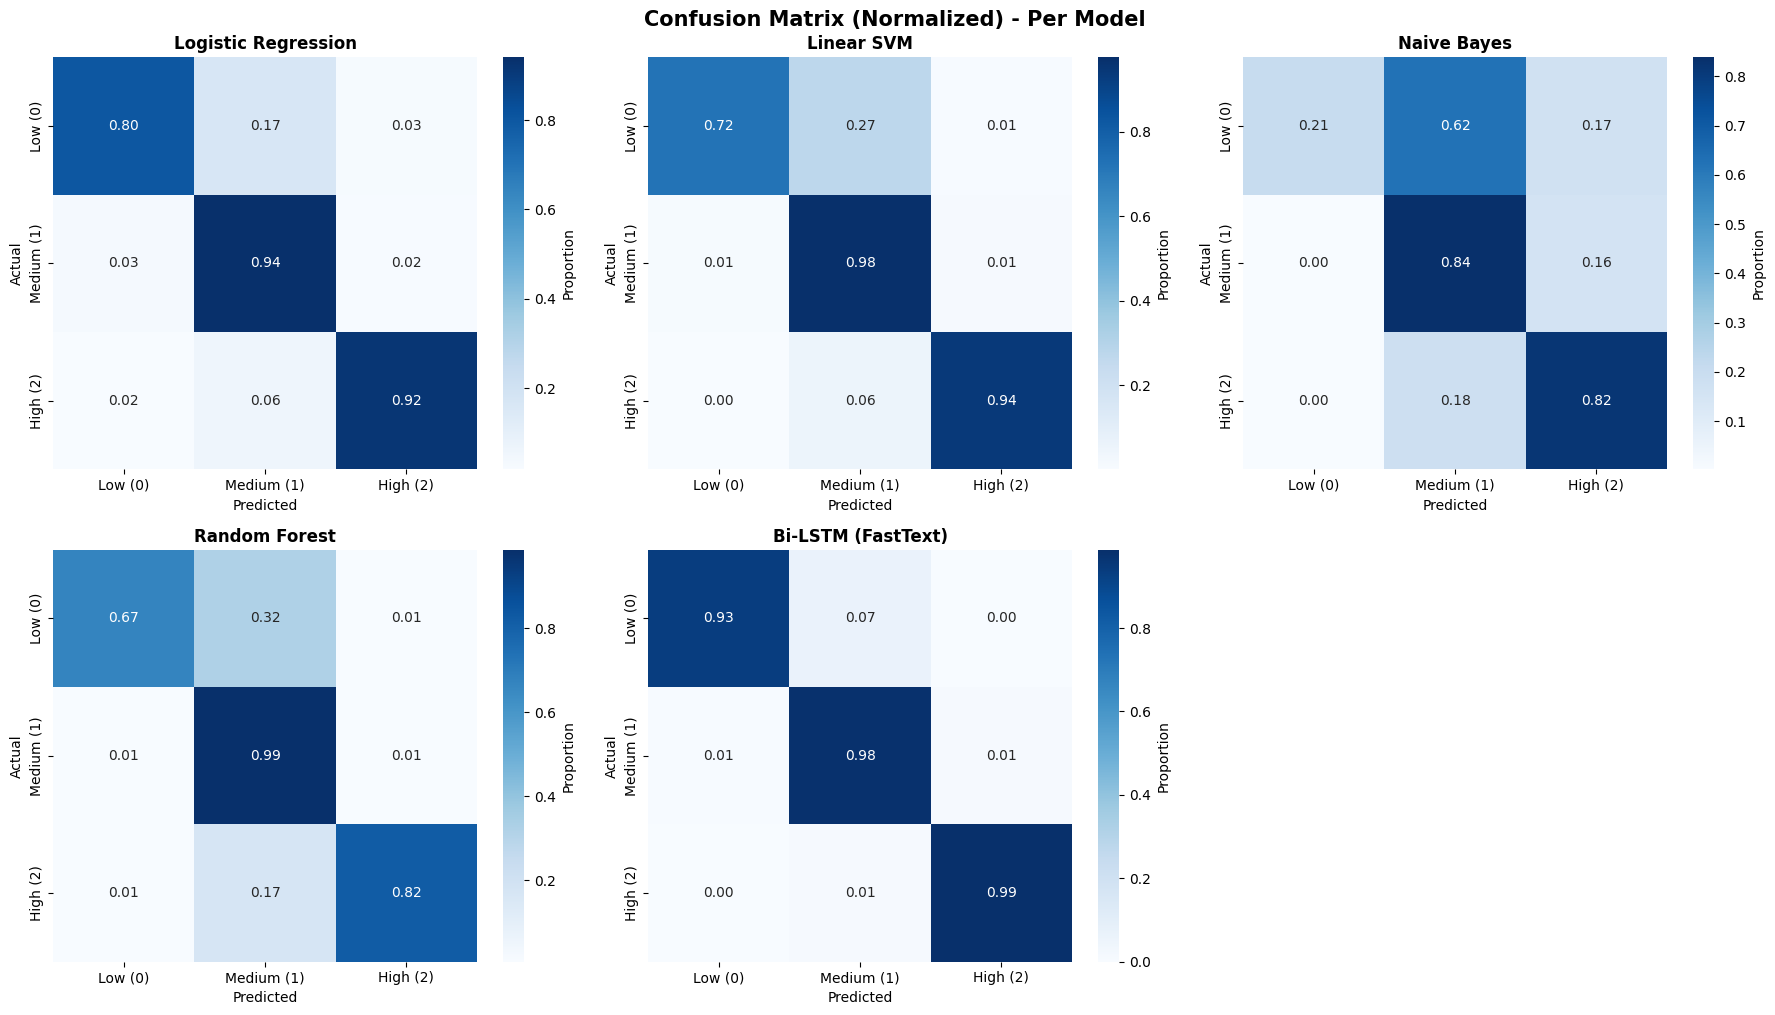

In [ ]:
def plot_confusion_matrices(y_true, predictions_dict, label_names):
    n = len(predictions_dict)
    cols = 3
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(18, 5*rows))
    axes = axes.flatten()

    for idx, (name, y_pred) in enumerate(predictions_dict.items()):
        ax = axes[idx]
        cm = confusion_matrix(y_true, y_pred)
        cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

        sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                    xticklabels=label_names, yticklabels=label_names, ax=ax,
                    cbar_kws={'label': 'Proportion'})
        ax.set_title(name, fontweight='bold')
        ax.set_xlabel('Predicted')
        ax.set_ylabel('Actual')

    for j in range(idx+1, len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.suptitle('Confusion Matrix (Normalized) - Per Model',
                 fontsize=15, fontweight='bold', y=1.01)
    plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
    plt.show()

# Kumpulkan prediksi
predictions_dict = {name: results_all[name]['y_pred'] for name in results_all}
plot_confusion_matrices(y_test, predictions_dict, label_names)

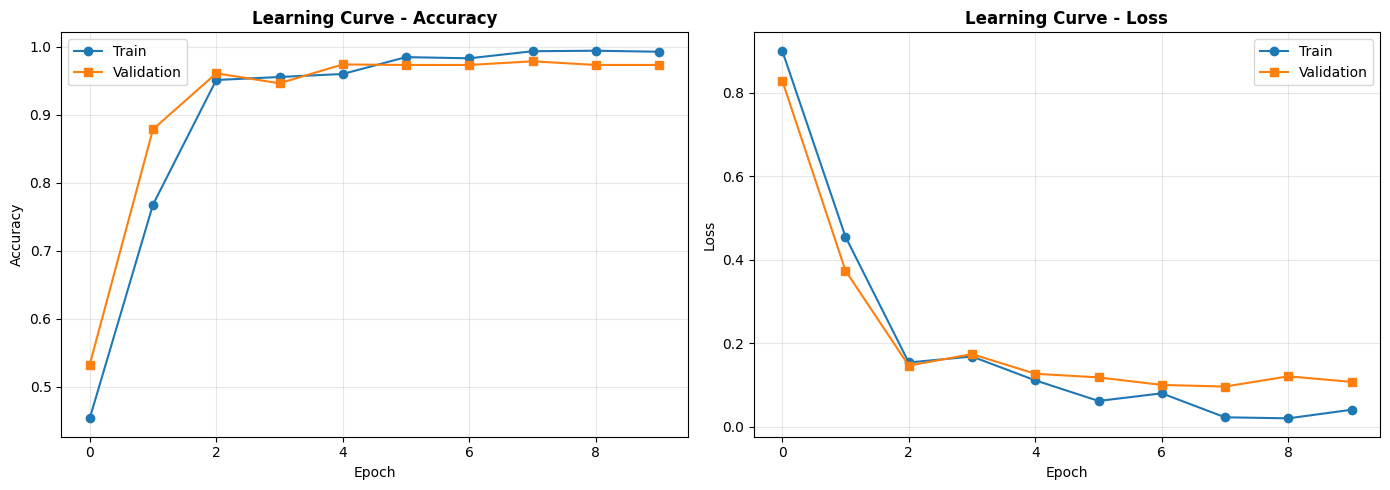

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'], label='Train', marker='o')
ax1.plot(history.history['val_accuracy'], label='Validation', marker='s')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy')
ax1.set_title('Learning Curve - Accuracy', fontweight='bold')
ax1.legend(); ax1.grid(True, alpha=0.3)

ax2.plot(history.history['loss'], label='Train', marker='o')
ax2.plot(history.history['val_loss'], label='Validation', marker='s')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
ax2.set_title('Learning Curve - Loss', fontweight='bold')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('lstm_learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Ambil 5 contoh error dari Bi-LSTM
errors_idx = np.where(y_test.values != y_pred_lstm)[0]
print(f"🔍 Total error Bi-LSTM: {len(errors_idx)} dari {len(y_test)} data\n")

for i, idx in enumerate(errors_idx[:5]):
    true_label = label_names[y_test.iloc[idx]]
    pred_label = label_names[y_pred_lstm[idx]]
    text = X_test.iloc[idx][:400]

    print(f"{'='*70}")
    print(f"Error #{i+1} | True: {true_label} | Pred: {pred_label}")
    print(f"Text: {text}...")
    print()

🔍 Total error Bi-LSTM: 28 dari 1301 data

Error #1 | True: Medium (1) | Pred: High (2)
Text: nama dyah widyaningsuh nama perusahaan pt sungchang indonesia npwp 0010711471052000 email import sungchang gmail com ijin menyampaikan terkait pelaporan bc 2 4 melalui ceisa saya baru saja membuat laporan bc 2 4 melalu ceisa 4 0 dengan nomor aju 000024 sug560 20261013 000003 tetapi nilai punggutannya tidak bisa muncul pada saat akan dicetak nilainya juga tidak sesuai dengan uraian yang ada jadi do...

Error #2 | True: High (2) | Pred: Medium (1)
Text: perihal laporan kendala teknis dokumen pemeriksaan fisik tidak muncul di menu rekam lhp gate in dan pembongkaran kepada yth tim ceisa care dengan hormat kami melaporkan adanya kendala teknis berupa tidak munculnya data dokumen dengan status pemeriksaan fisik pada menu rekam lhp di aplikasi ceisa kendala ini menghambat proses operasional dan penyelesaian administrasi kepabeanan kami adapun detail k...

Error #3 | True: Medium (1) | Pred: High (2)
T

In [14]:
# 1. Instalasi library
!pip install python-docx pandas scikit-learn -q

from docx import Document
from docx.shared import Pt, Inches
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT
from google.colab import files
import pandas as pd
from sklearn.metrics import classification_report

# Inisialisasi Dokumen
doc = Document()
style = doc.styles['Normal']
style.font.name = 'Times New Roman'
style.font.size = Pt(11)

# ==============================================================================
# AMBIL DATA ASLI DARI HASIL TRAINING COLAB ANDA
# ==============================================================================
try:
    # Mengambil laporan klasifikasi asli
    report_dict = classification_report(y_test, y_pred_lstm, target_names=['Low (0)', 'Medium (1)', 'High (2)'], output_dict=True)
    df_report = pd.DataFrame(report_dict).transpose()

    # Konversi ke persentase dan bulatkan 2 desimal (kecuali support yang tetap integer)
    df_report[['precision', 'recall', 'f1-score']] = (df_report[['precision', 'recall', 'f1-score']] * 100).round(2)
    df_report['support'] = df_report['support'].astype(int)

    # PENTING: Ubah index (nama kelas) menjadi kolom biasa agar mudah dimasukkan ke tabel Word
    df_report = df_report.reset_index()
    df_report = df_report.rename(columns={'index': 'Kelas Prioritas'})

    print("✅ Data asli berhasil diambil dari sesi Colab Anda!")
    print("\n📊 Preview Tabel 3 yang akan dimasukkan ke Word:")
    print(df_report.to_markdown(index=False))

except NameError:
    print("⚠️ PERINGATAN: Variabel 'y_test' atau 'y_pred_lstm' tidak ditemukan.")
    print("Silakan pastikan Anda sudah menjalankan cell training Bi-LSTM di Colab sebelum menjalankan skrip ini.")
    # Fallback data dummy jika variabel tidak ditemukan
    df_report = pd.DataFrame({
        'Kelas Prioritas': ['Low (0)', 'Medium (1)', 'High (2)', 'accuracy', 'macro avg', 'weighted avg'],
        'precision': [91.49, 95.85, 98.04, 96.15, 95.13, 96.21],
        'recall': [96.27, 97.38, 94.35, 96.15, 96.00, 96.15],
        'f1-score': [93.82, 96.61, 96.16, 96.15, 95.53, 96.16],
        'support': [268, 890, 142, None, 1300, 1300] # Contoh total ~1300
    })

# ==============================================================================
# MEMBUAT TABEL DI WORD (DINAMIS & ROBUST)
# ==============================================================================
doc.add_heading('Tabel 3. Metrik Performa Per-Kelas dari Model Bi-LSTM yang Diusulkan', level=2)

# Hitung jumlah baris dan kolom secara dinamis berdasarkan DataFrame
num_rows = len(df_report) + 1  # +1 untuk baris header
num_cols = len(df_report.columns) # Seharusnya 5

table = doc.add_table(rows=num_rows, cols=num_cols)
table.style = 'Table Grid'
table.alignment = WD_TABLE_ALIGNMENT.CENTER

# 1. Isi Header Tabel
headers_mapping = {
    'Kelas Prioritas': 'Kelas Prioritas',
    'precision': 'Presisi (%)',
    'recall': 'Recall (%)',
    'f1-score': 'F1-Skor (%)',
    'support': 'Support (Data Uji)'
}

for j, col_name in enumerate(df_report.columns):
    cell = table.rows[0].cells[j]
    cell.text = headers_mapping.get(col_name, col_name)
    for p in cell.paragraphs:
        p.alignment = WD_ALIGN_PARAGRAPH.CENTER
        for run in p.runs:
            run.bold = True
            run.font.size = Pt(10)

# 2. Isi Data Tabel
for i, (_, row) in enumerate(df_report.iterrows()):
    for j, val in enumerate(row):
        cell = table.rows[i+1].cells[j]

        # Format tampilan angka
        if isinstance(val, float):
            cell.text = f"{val:.2f}"
        elif pd.isna(val):
            cell.text = "-"
        else:
            cell.text = str(val)

        for p in cell.paragraphs:
            p.alignment = WD_ALIGN_PARAGRAPH.CENTER
            for run in p.runs:
                run.font.size = Pt(10)
                # Bold untuk baris ringkasan (accuracy, macro avg, weighted avg)
                kelas_nama = str(row['Kelas Prioritas']).lower()
                if kelas_nama in ['accuracy', 'macro avg', 'weighted avg']:
                    run.bold = True

# Catatan Kaki
note = doc.add_paragraph()
note.alignment = WD_ALIGN_PARAGRAPH.LEFT
run_note = note.add_run(
    "Catatan: 'Macro Avg' menghitung metrik secara independen untuk setiap kelas lalu dirata-ratakan, "
    "yang sangat krusial untuk mengevaluasi performa pada dataset yang tidak seimbang. "
    "'Support' merepresentasikan jumlah sebenarnya dari sampel kelas tersebut dalam data uji."
)
run_note.font.size = Pt(9)
# Sesuai permintaan sebelumnya, tidak ada italic. Jika ingin italic, hapus tanda pagar di bawah:
# run_note.italic = True

# Simpan dan Download
filename = 'Tabel_3_Performance_ASLI_Fix.docx'
doc.save(filename)
print(f"\n✅ File Word berhasil dibuat: {filename}")
files.download(filename)

✅ Data asli berhasil diambil dari sesi Colab Anda!

📊 Preview Tabel 3 yang akan dimasukkan ke Word:
| Kelas Prioritas   |   precision |   recall |   f1-score |   support |
|:------------------|------------:|---------:|-----------:|----------:|
| Low (0)           |       91.49 |    96.27 |      93.82 |       134 |
| Medium (1)        |       95.85 |    97.38 |      96.61 |       688 |
| High (2)          |       98.04 |    94.35 |      96.16 |       478 |
| accuracy          |       96.15 |    96.15 |      96.15 |         0 |
| macro avg         |       95.13 |    96    |      95.53 |      1300 |
| weighted avg      |       96.21 |    96.15 |      96.16 |      1300 |

✅ File Word berhasil dibuat: Tabel_3_Performance_ASLI_Fix.docx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>